In [14]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'''\usepackage{libertine}\usepackage{fontawesome5}\usepackage{xcolor}'''
plt.rcParams['ps.usedistiller'] = 'xpdf'
import seaborn as sns
sns.set_theme(style='ticks')

# Import implemented bayesian optimizers in the backend.
from bo import utility_bo, pairwise_bo, mixed_bo, generate_comparisons, generate_random_samples, generate_sobol_samples

In [15]:
def loop(objective, name, sample="random", algo="random", dim=5, trials=5, max_iter=20):
    df = pd.DataFrame(columns=["sampler", "objective", "algo", "trial", "iteration", "best_y"])
    for t in range(trials):
        if sample == "random":
            X, y = generate_random_samples(objective, n=5, dim=dim)
        elif sample == "sobol":
            X, y = generate_sobol_samples(objective, n=5, dim=dim)
        for i in range(5):
            df = df.append({"sampler": sample, "objective": name, "algo": algo, "trial": t, "iteration": i, "best_y": y[i].item()}, ignore_index=True)

        # reset all history
        next_X = None
        next_y = None
        comps  = None
        for i in range(5, max_iter):
            if algo == "random":
                next_X = torch.rand(2, dim, dtype=torch.float32)
            elif algo == "pointwise":
                next_X = utility_bo(X, y.reshape(-1, 1), dim=dim)[0]
            elif algo == "pairwise":
                comps = generate_comparisons(y)
                next_X, _ = pairwise_bo(X, comps, dim=dim)
            elif algo == "listwise":
                comps = generate_comparisons(y)
                next_X, _ = mixed_bo(X, comps, dim=dim)
            else:
                raise ValueError("Unknown algo: {}".format(algo))
            next_y = objective(next_X)
            best_y = torch.max(next_y)
            X = torch.cat([X, next_X])
            y = torch.cat([y, next_y])
            df = df.append({"sampler": sample, "objective": name, "algo": algo, "trial": t, "iteration": i, "best_y": best_y.item()}, ignore_index=True)
    return df

In [84]:
from botorch.test_functions import Hartmann, Ackley, Levy
from botorch.utils.transforms import unnormalize

dtype=torch.float32
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
objectives = {}

def utility_weightedsum(X):
    weighted_X = X * torch.sqrt(torch.arange(X.size(-1), dtype=dtype) + 1)
    return torch.sum(weighted_X, dim=-1)

objectives["weightedsum"] = (utility_weightedsum, 5)

hart6 = Hartmann(dim=6).to(device=device, dtype=dtype)
dim = hart6.dim
def utility_hart6(x):
    """This is a helper function we use to unnormalize and evalaute a point"""
    return hart6(unnormalize(x, hart6.bounds))

objectives["hart6"] = (utility_hart6, dim)

def utility_levy(x):
    X_unnorm = (20.0 * x) - 10.0
    levy = Levy(dim=10, negate=True)
    return -levy.evaluate_true(X_unnorm)

objectives["levy"] = (utility_levy, 10)

fun = Ackley(dim=20, negate=True).to(dtype=dtype, device=device)
fun.bounds[0, :].fill_(-5)
fun.bounds[1, :].fill_(10)
dim = fun.dim
def ackley(x):
    """This is a helper function we use to unnormalize and evalaute a point"""
    return fun(unnormalize(x, fun.bounds))

objectives["ackley"] = (ackley, dim)

In [85]:
objectives

{'weightedsum': (<function __main__.utility_weightedsum(X)>, 5),
 'hart6': (<function __main__.utility_hart6(x)>, 6),
 'levy': (<function __main__.utility_levy(x)>, 10),
 'ackley': (<function __main__.ackley(x)>, 20)}

In [96]:
torch.manual_seed(0)
np.random.seed(0)

sampl = ["random", "sobol"]
algos = ["random", "pointwise", "pairwise", "listwise"]

def optimize(name):
    df = pd.DataFrame()
    utility, dim = objectives[name]
    for samp in sampl:
        for algo in algos:
            print(name, samp, algo)
            df_utility = loop(utility, name, dim=dim, sample=samp, algo=algo, trials=5, max_iter=20)
            df = df.append(df_utility, ignore_index=True)
    return df

In [97]:
df1 = optimize("weightedsum")

weightedsum random random
weightedsum random pointwise
weightedsum random pairwise
weightedsum random listwise
weightedsum sobol random
weightedsum sobol pointwise
weightedsum sobol pairwise
weightedsum sobol listwise


In [91]:
df2 = optimize("hart6")

hart6 random random
hart6 random pointwise
hart6 random pairwise
hart6 random listwise
hart6 sobol random
hart6 sobol pointwise
hart6 sobol pairwise
hart6 sobol listwise


In [92]:
df3 = optimize("levy")

levy random random
levy random pointwise
levy random pairwise
levy random listwise
levy sobol random
levy sobol pointwise
levy sobol pairwise
levy sobol listwise


In [129]:
df4 = optimize("ackley")

ackley random random
ackley random pointwise
ackley random pairwise
ackley random listwise
ackley sobol random
ackley sobol pointwise
ackley sobol pairwise
ackley sobol listwise


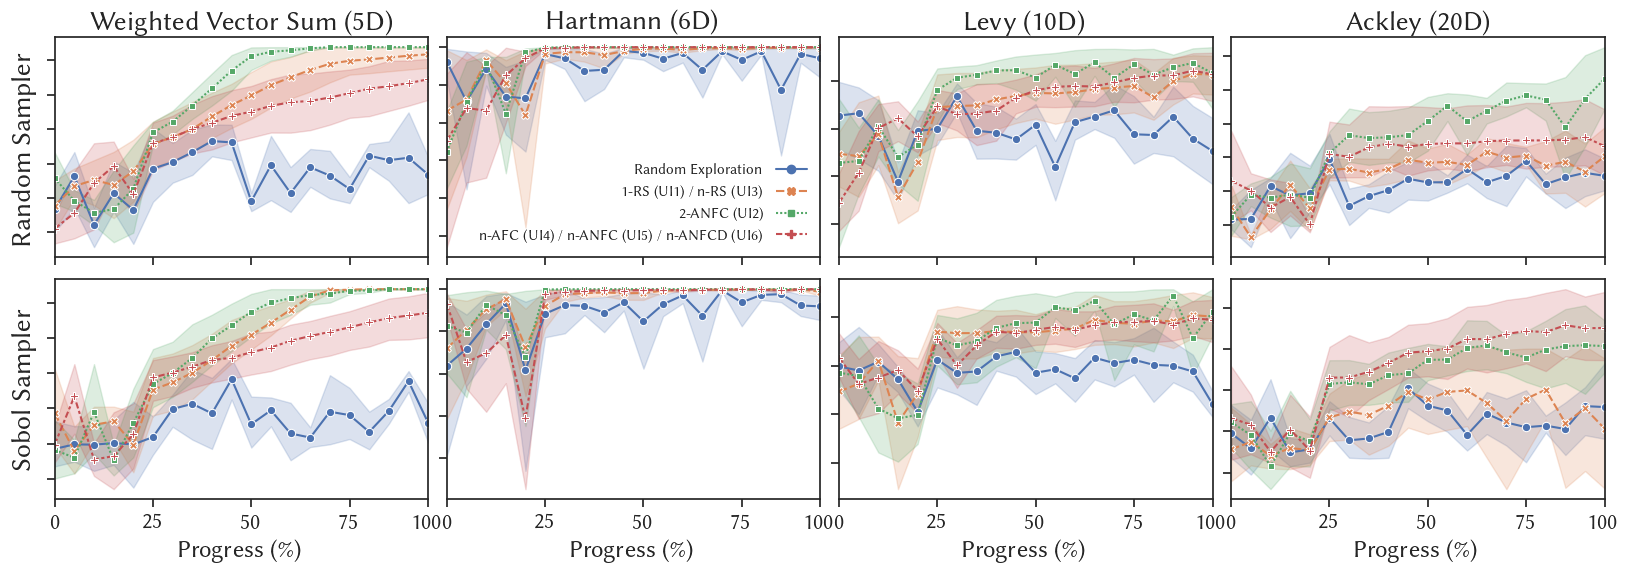

In [130]:
df = pd.concat([df1, df2, df3, df4], ignore_index=True)

fig, ax = plt.subplots(2, 4, figsize=(20, 6), gridspec_kw = {'wspace': 0.05, 'hspace': 0.1})
sns.lineplot(ax=ax[0][0], data=df[(df.objective == "weightedsum") & (df.sampler == "random")], x="iteration", y="best_y", hue="algo", style="algo", markers=True)
sns.lineplot(ax=ax[0][1], data=df[(df.objective == "hart6") & (df.sampler == "random")], x="iteration", y="best_y", hue="algo", style="algo", markers=True)
sns.lineplot(ax=ax[0][2], data=df[(df.objective == "levy") & (df.sampler == "random")], x="iteration", y="best_y", hue="algo", style="algo", markers=True)
sns.lineplot(ax=ax[0][3], data=df[(df.objective == "ackley") & (df.sampler == "random")], x="iteration", y="best_y", hue="algo", style="algo", markers=True)
sns.lineplot(ax=ax[1][0], data=df[(df.objective == "weightedsum") & (df.sampler == "sobol")], x="iteration", y="best_y", hue="algo", style="algo", markers=True)
sns.lineplot(ax=ax[1][1], data=df[(df.objective == "hart6") & (df.sampler == "sobol")], x="iteration", y="best_y", hue="algo", style="algo", markers=True)
sns.lineplot(ax=ax[1][2], data=df[(df.objective == "levy") & (df.sampler == "sobol")], x="iteration", y="best_y", hue="algo", style="algo", markers=True)
sns.lineplot(ax=ax[1][3], data=df[(df.objective == "ackley") & (df.sampler == "sobol")], x="iteration", y="best_y", hue="algo", style="algo", markers=True)

# ax[0][0].axhline(8.38233, color='black', ls='--')
# ax[0][1].axhline(-3.32237, color='black', ls='--')
# ax[0][2].axhline(0, color='black', ls='--')
# ax[0][3].axhline(0, color='black', ls='--')
# ax[1][0].axhline(8.38233, color='black', ls='--')
# ax[1][1].axhline(-3.32237, color='black', ls='--')
# ax[1][2].axhline(0, color='black', ls='--')
# ax[1][3].axhline(0, color='black', ls='--')

ax[0][0].set_title("Weighted Vector Sum (5D)", fontsize=20)
ax[0][1].set_title("Hartmann (6D)", fontsize=20)
ax[0][2].set_title("Levy (10D)", fontsize=20)
ax[0][3].set_title("Ackley (20D)", fontsize=20)
ax[0][0].set_ylabel("Random Sampler", fontsize=20)
ax[1][0].set_ylabel("Sobol Sampler", fontsize=20)

ax[0][0].set_xlabel("")
ax[0][1].set_xlabel("")
ax[0][2].set_xlabel("")
ax[0][3].set_xlabel("")
ax[0][0].set_xticklabels([])
ax[0][1].set_xticklabels([])
ax[0][2].set_xticklabels([])
ax[0][3].set_xticklabels([])

ax[0][0].set_xlim(0, 19)
ax[0][1].set_xlim(0, 19)
ax[0][2].set_xlim(0, 19)
ax[0][3].set_xlim(0, 19)
ax[1][0].set_xlim(0, 19)
ax[1][1].set_xlim(0, 19)
ax[1][2].set_xlim(0, 19)
ax[1][3].set_xlim(0, 19)

ax[0][0].set_xticks([0, 5, 10, 15, 19])
ax[0][1].set_xticks([0, 5, 10, 15, 19])
ax[0][2].set_xticks([0, 5, 10, 15, 19])
ax[0][3].set_xticks([0, 5, 10, 15, 19])
ax[1][0].set_xticks([0, 5, 10, 15, 19])
ax[1][1].set_xticks([0, 5, 10, 15, 19])
ax[1][2].set_xticks([0, 5, 10, 15, 19])
ax[1][3].set_xticks([0, 5, 10, 15, 19])
ax[1][0].set_xticklabels([0, 25, 50, 75, 100], fontsize=16)
ax[1][1].set_xticklabels([0, 25, 50, 75, 100], fontsize=16)
ax[1][2].set_xticklabels([0, 25, 50, 75, 100], fontsize=16)
ax[1][3].set_xticklabels([0, 25, 50, 75, 100], fontsize=16)

ax[0][1].set_ylabel("")
ax[0][2].set_ylabel("")
ax[0][3].set_ylabel("")
ax[1][1].set_ylabel("")
ax[1][2].set_ylabel("")
ax[1][3].set_ylabel("")
ax[0][0].set_yticklabels([])
ax[0][1].set_yticklabels([])
ax[0][2].set_yticklabels([])
ax[0][3].set_yticklabels([])
ax[1][0].set_yticklabels([])
ax[1][1].set_yticklabels([])
ax[1][2].set_yticklabels([])
ax[1][3].set_yticklabels([])

ax[1][0].set_xlabel("Progress (\%)", fontsize=18)
ax[1][1].set_xlabel("Progress (\%)", fontsize=18)
ax[1][2].set_xlabel("Progress (\%)", fontsize=18)
ax[1][3].set_xlabel("Progress (\%)", fontsize=18)

legend_labels = [
    "Random Exploration",
    "1-RS (UI1) / n-RS (UI3)",
    "2-ANFC (UI2)",
    "n-AFC (UI4) / n-ANFC (UI5) / n-ANFCD (UI6)",
]
ax[0][1].legend(markerfirst=False, loc="lower right", fontsize=11)
leg = ax[0][1].get_legend()
for t, l in zip(leg.texts, legend_labels):
    t.set_text(l)
leg.set_frame_on(False)
leg.set_title("")
# leg.set_bbox_to_anchor((1.05, 1))
ax[0][0].legend().remove()
ax[0][2].legend().remove()
ax[0][3].legend().remove()
ax[1][0].legend().remove()
ax[1][1].legend().remove()
ax[1][2].legend().remove()
ax[1][3].legend().remove()

plt.tight_layout()
plt.savefig("bo_simulation.pdf", bbox_inches="tight")